In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix,roc_auc_score,classification_report)
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
!pip install shap
import shap
import os

In [ ]:
data_free = np.load("clean_final_spec.npy")
spectra_free = data_free[:,:52]
label_free = np.zeros(len(spectra_free)) #0-free chem

In [ ]:
spectra_eq = np.load('eq_chemistry_spectra.npy')
label_eq   = np.ones(len(spectra_eq))

In [ ]:
n_free = len(spectra_free)      # 98,495
n_eq   = len(spectra_eq)        # 113,176

print(f"Free chemistry:        {n_free}")
print(f"Equilibrium chemistry: {n_eq}")

Free chemistry:        98495
Equilibrium chemistry: 113176


In [ ]:
n_use = min(n_free, n_eq)
print(f"Using {n_use} from each class")

Using 98495 from each class


In [ ]:
np.random.seed(42)
eq_idx = np.random.choice(n_eq, n_use, replace=False)
spectra_eq_balanced = spectra_eq[eq_idx]
label_eq = label_eq[eq_idx]
print(f"\nFinal dataset:")
print(f"Free chemistry:        {n_use} spectra — label 0")
print(f"Equilibrium chemistry: {n_use} spectra — label 1")
print(f"Total:                 {n_use*2} spectra")


Final dataset:
Free chemistry:        98495 spectra — label 0
Equilibrium chemistry: 98495 spectra — label 1
Total:                 196990 spectra


In [ ]:
# ── ADD GAUSSIAN NOISE (30ppm) TO CHECK ROBUSTNESS ───────────────────────────
noise_std = 30e-6  # 30 ppm

np.random.seed(42)
spectra_free = spectra_free + np.random.normal(0, noise_std, spectra_free.shape)
spectra_eq_balanced = spectra_eq_balanced + np.random.normal(0, noise_std, spectra_eq_balanced.shape)

print(f"Noise std added: {noise_std}")
print(f"Free chem spectra range: [{spectra_free.min():.6f}, {spectra_free.max():.6f}]")
print(f"Eq chem spectra range:   [{spectra_eq_balanced.min():.6f}, {spectra_eq_balanced.max():.6f}]")

Noise std added: 3e-05
Free chem spectra range: [-0.002008, 0.534858]
Eq chem spectra range:   [-0.024558, 0.708934]


In [ ]:
spectra_free_norm = spectra_free / spectra_free.mean(axis=1,keepdims=True)
spectra_eq_norm   = spectra_eq_balanced  / spectra_eq_balanced.mean(axis=1,keepdims=True)

print(f"Shape of normalised Free chemistry spectra: {spectra_free_norm.shape}")
print(f"Shape of normalised Equilibrium chemistry spectra: {spectra_eq_norm.shape}")

Shape of normalised Free chemistry spectra: (98495, 52)
Shape of normalised Equilibrium chemistry spectra: (98495, 52)


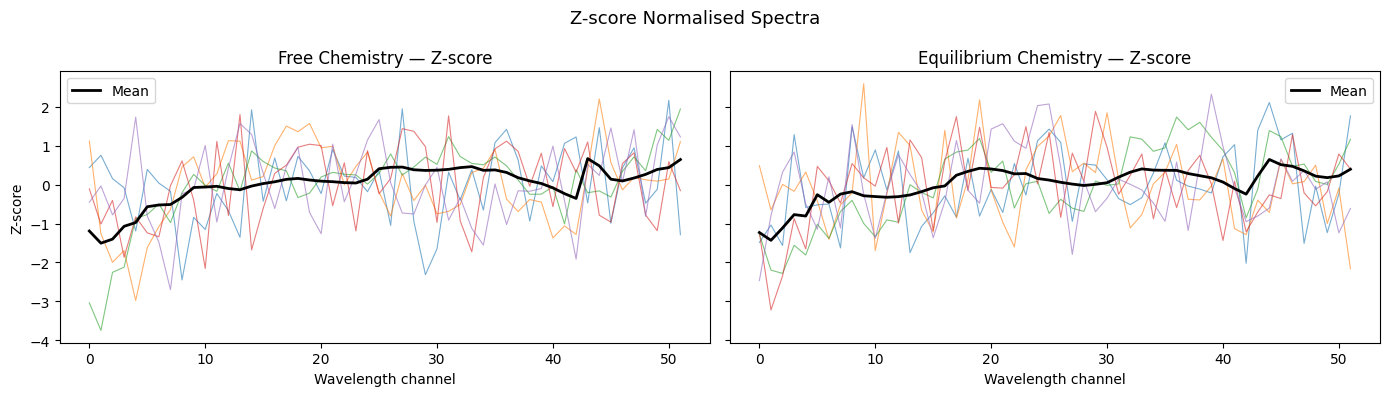

In [ ]:
# ── Z-SCORE NORMALISATION ─────────────────────────────────────────────────────
def zscore_per_spectrum(X):
    mean = X.mean(axis=1, keepdims=True)
    std  = X.std(axis=1,  keepdims=True)
    return (X - mean) / (std + 1e-8)  # 1e-8 to avoid division by zero

spectra_free_zscore = zscore_per_spectrum(spectra_free)
spectra_eq_zscore   = zscore_per_spectrum(spectra_eq_balanced)
# ── Side by side visual ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

# plot 5 random samples from each class for clarity
np.random.seed(42)
idx_free = np.random.choice(len(spectra_free_zscore), 5, replace=False)
idx_eq   = np.random.choice(len(spectra_eq_zscore),   5, replace=False)

for i in idx_free:
    axes[0].plot(spectra_free_zscore[i], alpha=0.6, linewidth=0.8)
axes[0].plot(spectra_free_zscore.mean(axis=0), color='black', linewidth=2, label='Mean')
axes[0].set_title('Free Chemistry — Z-score')
axes[0].set_xlabel('Wavelength channel')
axes[0].set_ylabel('Z-score')
axes[0].legend()

for i in idx_eq:
    axes[1].plot(spectra_eq_zscore[i], alpha=0.6, linewidth=0.8)
axes[1].plot(spectra_eq_zscore.mean(axis=0), color='black', linewidth=2, label='Mean')
axes[1].set_title('Equilibrium Chemistry — Z-score')
axes[1].set_xlabel('Wavelength channel')
axes[1].legend()

plt.suptitle('Z-score Normalised Spectra', fontsize=13)
plt.tight_layout()
plt.savefig('zscore_spectra_visual.png', dpi=150)
plt.show()

In [ ]:
X = np.vstack([spectra_free_norm, spectra_eq_norm]).astype(np.float32)
y = np.concatenate([label_free, label_eq]).astype(np.float32)
print(f"Total dataset: {X.shape}")
print(f"Class balance: {y.mean():.3f}")

Total dataset: (196990, 52)
Class balance: 0.500


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)
print(f"Train: {X_train.shape}")
print(f"Val:   {X_val.shape}")
print(f"Test:  {X_test.shape}")

Train: (157592, 52)
Val:   (19699, 52)
Test:  (19699, 52)


In [ ]:
def to_tensor(X,y):
  return(torch.tensor(X).unsqueeze(1),torch.tensor(y).unsqueeze(1))

X_train_t,y_train_t = to_tensor(X_train,y_train)
X_test_t,y_test_t = to_tensor(X_test,y_test)
X_val_t,y_val_t = to_tensor(X_val,y_val)

In [ ]:
train_loader = DataLoader(TensorDataset(X_train_t,y_train_t),batch_size=256,shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t),batch_size=256)

In [ ]:
class SpectralChemistryClassifier(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv_block = nn.Sequential(
        #block 1 (52 -> 26)
        nn.Conv1d(1,32,kernel_size=5,padding=2),
        nn.ReLU(),
        nn.MaxPool1d(2),

        #block 2 (26 -> 13)
        nn.Conv1d(32,64,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool1d(2),

        #block 3 (13 -> 6)
        nn.Conv1d(64,128,kernel_size=3,padding=1),
        nn.ReLU()
    )

    self.global_pool = nn.AdaptiveAvgPool1d(1)

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(64,1),
        nn.Sigmoid()
    )

  def forward(self,x):
    x = self.conv_block(x)
    x = self.global_pool(x)
    x = self.classifier(x)
    return x

model_clf = SpectralChemistryClassifier()
print(model_clf)
total_params = sum(p.numel() for p in model_clf.parameters())
print(f"\nTotal parameters: {total_params:,}")

SpectralChemistryClassifier(
  (conv_block): Sequential(
    (0): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): ReLU()
  )
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
    (5): Sigmoid()
  )
)

Total parameters: 39,425


# Training

In [ ]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model_clf.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

n_epochs = 50
train_losses, val_losses, val_accs = [], [], []
best_val_loss = float('inf')

In [ ]:
from torch.nn.modules import loss
if("best_classifier.pth" not in os.listdir()):
  for epoch in range(n_epochs):
    # train
    model_clf.train()
    batch_losses = []
    for X_batch,y_batch in train_loader:
      optimizer.zero_grad()
      pred = model_clf(X_batch)
      loss = criterion(pred,y_batch)
      loss.backward()
      optimizer.step()
      batch_losses.append(loss.item())

    train_loss = np.mean(batch_losses)
    train_losses.append(train_loss)

    # val
    model_clf.eval()
    with torch.no_grad():
      val_pred = model_clf(X_val_t)
      val_loss = criterion(val_pred,y_val_t).item()
      val_acc = ((val_pred > 0.5).float() == y_val_t).float().mean().item()

    val_losses.append(val_loss)
    val_accs.append(val_acc)
    scheduler.step(val_loss)

    # save the best
    if val_loss < best_val_loss:
      best_val_loss = val_loss
      torch.save(model_clf.state_dict(), 'best_classifier.pth')

    if epoch % 5 == 0:
      print(f"Epoch {epoch:3d} | "f"Train Loss: {train_loss:.4f} | "f"Val Loss: {val_loss:.4f} | "f"Val Acc: {val_acc:.4f}")


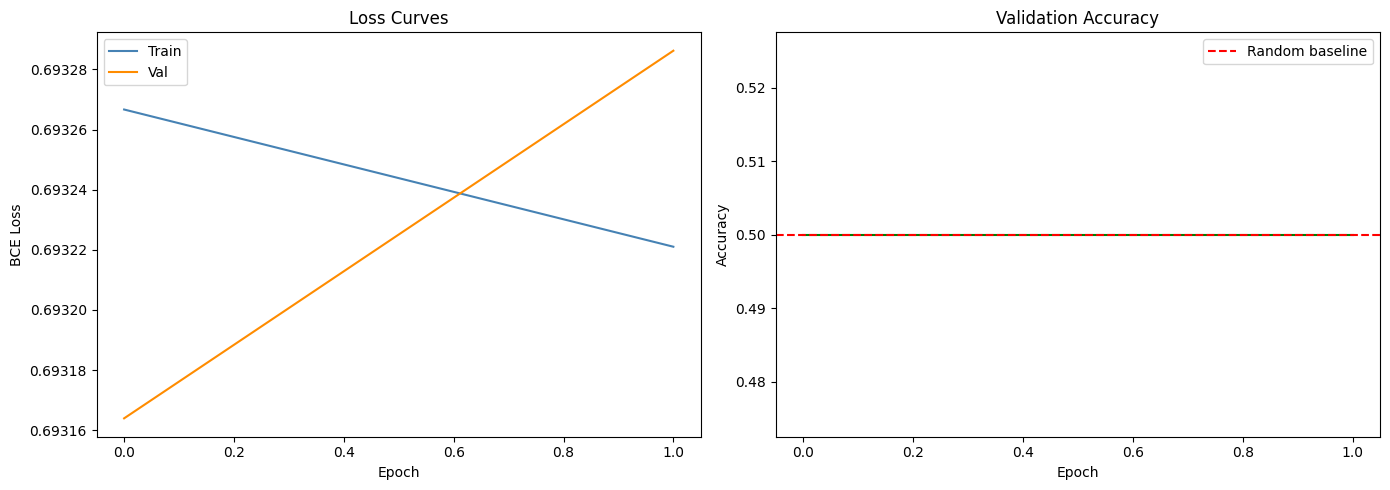

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label='Train', color='steelblue')
axes[0].plot(val_losses,   label='Val',   color='darkorange')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Loss Curves')
axes[0].legend()

axes[1].plot(val_accs, color='green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy')
axes[1].axhline(0.5, color='red', linestyle='--', label='Random baseline')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

# Testing

In [ ]:
model_clf.load_state_dict(torch.load('best_classifier.pth'))
model_clf.eval()

with torch.no_grad():
  test_pred = model_clf(X_test_t).numpy().flatten()
  test_labels = (test_pred > 0.5).astype(float)
  print(test_labels)

[1. 1. 1. ... 0. 0. 1.]


In [ ]:
y_test_np = y_test if isinstance(y_test, np.ndarray) else y_test.numpy()
y_test_np = y_test_np.astype(float)
auc = roc_auc_score(y_test, test_pred)
print(f"Test Accuracy : {(test_labels == y_test).mean():.4f}")
print(f"ROC-AUC Score : {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_labels,target_names=['Free', 'Equilibrium']))

Test Accuracy : 0.7422
ROC-AUC Score : 0.7554

Classification Report:
              precision    recall  f1-score   support

        Free       0.81      0.64      0.71      9850
 Equilibrium       0.70      0.85      0.77      9849

    accuracy                           0.74     19699
   macro avg       0.75      0.74      0.74     19699
weighted avg       0.75      0.74      0.74     19699



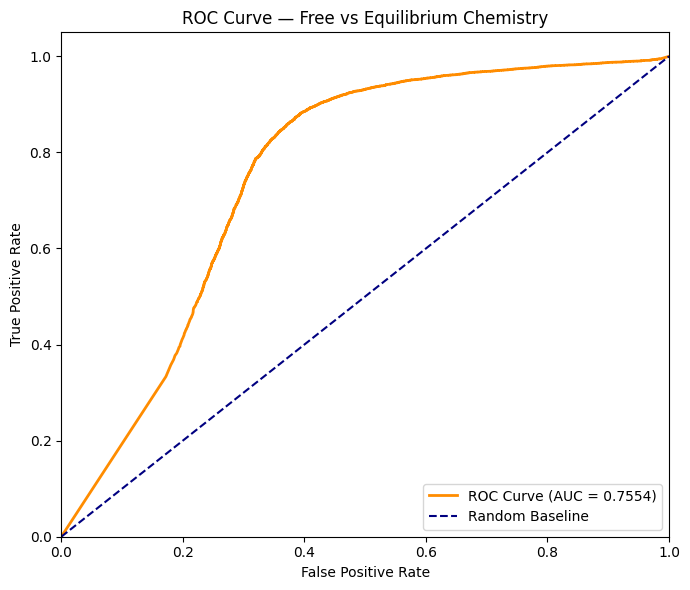

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, test_pred)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Baseline')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Free vs Equilibrium Chemistry')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150)
plt.show()

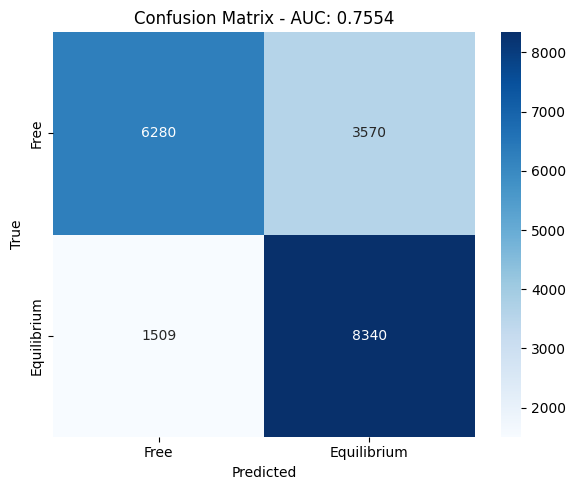

In [ ]:
cm = confusion_matrix(y_test, test_labels)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=['Free', 'Equilibrium'],yticklabels=['Free', 'Equilibrium'])
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix - AUC: {auc:.4f}')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

# Random Run

In [ ]:
idx = np.random.choice(len(X_test))
sample = X_test[idx]
true_label = y_test[idx]
print(f"This spectra is of {'Equilibrium' if true_label else 'Free'} Chemistry.")

This spectra is of Equilibrium Chemistry.


In [ ]:
sample_t = torch.tensor(sample,dtype=torch.float32)
sample_t = sample_t.unsqueeze(0).unsqueeze(0)  # (1, 1, 52)

In [ ]:
model_clf.load_state_dict(torch.load('best_classifier.pth'))
model_clf.eval()

with torch.no_grad():
    prob = model_clf(sample_t).item()
    pred_label = 1 if prob > 0.5 else 0
print(f"Predicted : {'Equilibrium' if pred_label else 'Free'}")
print(f"Confidence : {prob:.4f}")
print(f"Correct : {pred_label == int(true_label)}")

Predicted : Equilibrium
Confidence : 1.0000
Correct : True


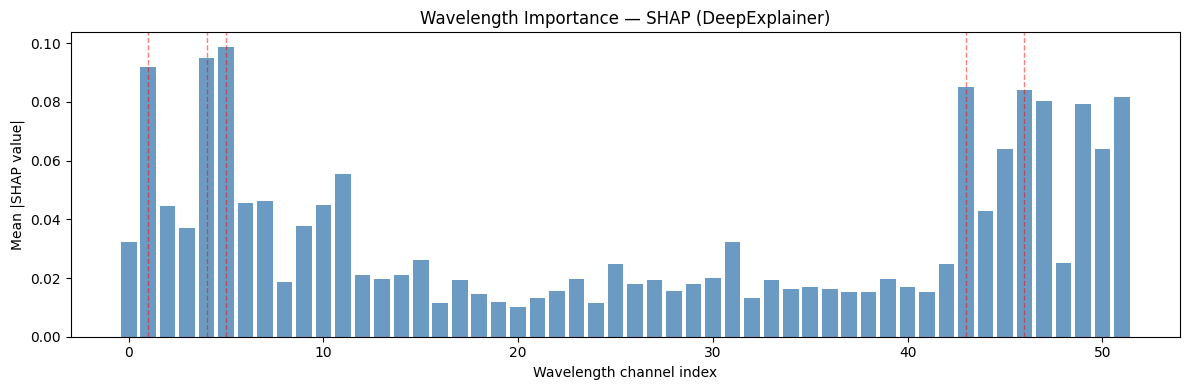

Top-5 most important wavelength channels: [5, 4, 1, 43, 46]


In [ ]:

model_clf.load_state_dict(torch.load('best_classifier.pth'))
model_clf.eval()

# DeepExplainer needs a background dataset — use a random subset of training data
background = X_train_t[:200]  # 200 samples is usually enough

explainer = shap.DeepExplainer(model_clf, background)
shap_values = explainer.shap_values(X_test_t[:500])  # explain first 500 test samples

# shap_values shape: (500, 1, 52) — squeeze the channel dim
shap_vals = np.array(shap_values).squeeze()  # → (500, 52)

# Mean absolute SHAP per wavelength channel
mean_shap = np.abs(shap_vals).mean(axis=0)  # → (52,)
wavelengths = np.arange(X_train.shape[1])   # replace with actual nm values if you have them

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(wavelengths, mean_shap, color='steelblue', alpha=0.8)
ax.set_xlabel('Wavelength channel index')
ax.set_ylabel('Mean |SHAP value|')
ax.set_title('Wavelength Importance — SHAP (DeepExplainer)')
top5 = np.argsort(mean_shap)[-5:][::-1]
for idx in top5:
    ax.axvline(idx, color='red', linestyle='--', alpha=0.5, linewidth=1)
plt.tight_layout()
plt.savefig('shap_wavelength_importance.png', dpi=150)
plt.show()
print(f'Top-5 most important wavelength channels: {top5.tolist()}')

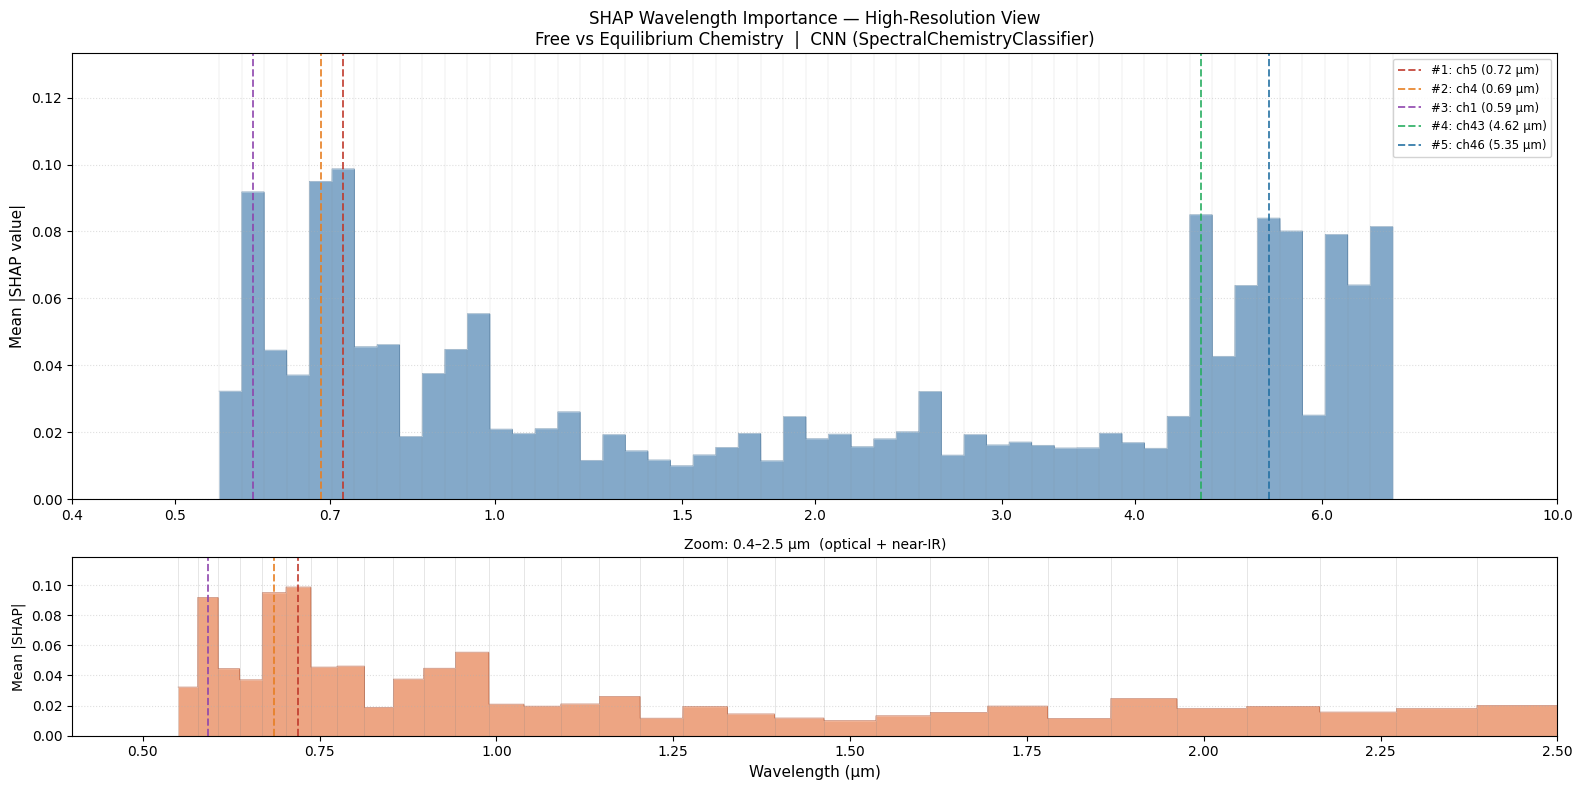

In [ ]:
# ── SHAP on High-Resolution Wavelength Grid ───────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── 1. Reconstruct the 52-channel wavelength bin edges and centres ────────────
# We assume log-uniform spacing matching POSEIDON's native grid structure
n_channels = 52
wl_min, wl_max = 0.55, 7.0

# 53 edges → 52 bins
wl_edges   = np.logspace(np.log10(wl_min), np.log10(wl_max), n_channels + 1)
wl_centres = 0.5 * (wl_edges[:-1] + wl_edges[1:])   # midpoint of each bin

# ── 2. High-res wavelength grid (same as POSEIDON's native grid) ──────────────
wl_highres = np.logspace(np.log10(wl_min), np.log10(wl_max), 48283)

# ── 3. Smear each channel's SHAP value across its bin on the high-res grid ────
# For each high-res point, find which of the 52 bins it belongs to,
# then assign that bin's mean |SHAP| value to it.
# np.searchsorted finds the bin index for every high-res wavelength.
bin_indices   = np.searchsorted(wl_edges, wl_highres, side='right') - 1
bin_indices   = np.clip(bin_indices, 0, n_channels - 1)  # clamp edges
shap_highres  = mean_shap[bin_indices]   # mean_shap is your (52,) array from earlier

# ── 4. Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(16, 8),
                         gridspec_kw={'height_ratios': [2.5, 1]})

# ── Top panel: full wavelength range ─────────────────────────────────────────
ax = axes[0]
ax.fill_between(wl_highres, shap_highres, alpha=0.75, color='#5B8DB8', linewidth=0)
ax.plot(wl_highres, shap_highres, color='#2C5F8A', linewidth=0.4, alpha=0.6)

# Mark bin boundaries as faint vertical lines
for edge in wl_edges:
    ax.axvline(edge, color='grey', linewidth=0.3, alpha=0.3)

# Annotate known molecular absorption bands
# bands = [
#     (0.90, 1.00,  '#A9DFBF', 'H₂O\n0.94'),
#     (1.10, 1.20,  '#A9DFBF', 'H₂O\n1.14'),
#     (1.32, 1.48,  '#A9DFBF', 'H₂O\n1.38'),
#     (1.80, 1.96,  '#A9DFBF', 'H₂O\n1.87'),
#     (2.60, 2.85,  '#FDEBD0', 'H₂O\nCO₂'),
#     (1.62, 1.72,  '#D7BDE2', 'CH₄\n1.67'),
#     (2.20, 2.40,  '#D7BDE2', 'CH₄\n2.3'),
#     (4.20, 4.45,  '#FADBD8', 'CO₂\n4.3'),
#     (4.60, 4.85,  '#F9E79F', 'CO\n4.7'),
#     (6.10, 6.60,  '#A9DFBF', 'H₂O\n6.3'),
#     (7.60, 7.90,  '#D7BDE2', 'CH₄\n7.7'),
#     (9.90, 10.05, '#FAD7A0', 'NH₃\n10'),
# ]

ymax = shap_highres.max() * 1.35
# for x0, x1, col, label in bands:
#     ax.axvspan(x0, x1, alpha=0.22, color=col, zorder=0)
#     ax.text((x0+x1)/2, ymax * 0.92, label, ha='center', va='top',
#             fontsize=7.5, color='#555555', fontweight='bold')

# Mark top-5 channel centres
top5 = np.argsort(mean_shap)[-5:][::-1]
colors_top = ['#C0392B','#E67E22','#8E44AD','#27AE60','#2471A3']
for rank, ch in enumerate(top5):
    wl = wl_centres[ch]
    ax.axvline(wl, color=colors_top[rank], linewidth=1.4,
               linestyle='--', alpha=0.85,
               label=f'#{rank+1}: ch{ch} ({wl:.2f} μm)')

ax.set_xscale('log')
ax.set_xlim(wl_min, wl_max)
ax.set_ylim(0, ymax)
ax.set_ylabel('Mean |SHAP value|', fontsize=11)
ax.set_title('SHAP Wavelength Importance — High-Resolution View\n'
             'Free vs Equilibrium Chemistry  |  CNN (SpectralChemistryClassifier)',
             fontsize=12)
ax.legend(fontsize=8.5, loc='upper right', framealpha=0.85)
ax.set_xticks([0.4, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 10.0])
ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
ax.tick_params(axis='x', which='minor', bottom=False)
ax.grid(axis='y', linestyle=':', alpha=0.4)

# ── Bottom panel: zoomed into 0.4–2.5 μm (where top channels cluster) ────────
ax2 = axes[1]
mask = wl_highres <= 2.5
ax2.fill_between(wl_highres[mask], shap_highres[mask],
                 alpha=0.75, color='#E8875A', linewidth=0)
ax2.plot(wl_highres[mask], shap_highres[mask],
         color='#B05030', linewidth=0.5, alpha=0.7)

for edge in wl_edges[wl_edges <= 2.5]:
    ax2.axvline(edge, color='grey', linewidth=0.4, alpha=0.35)

# for x0, x1, col, label in bands:
#     if x0 <= 2.5:
#         ax2.axvspan(x0, min(x1, 2.5), alpha=0.22, color=col, zorder=0)

for rank, ch in enumerate(top5):
    wl = wl_centres[ch]
    if wl <= 2.5:
        ax2.axvline(wl, color=colors_top[rank], linewidth=1.4,
                    linestyle='--', alpha=0.85)

ax2.set_xlim(0.4, 2.5)
ax2.set_ylim(0, shap_highres[mask].max() * 1.2)
ax2.set_xlabel('Wavelength (μm)', fontsize=11)
ax2.set_ylabel('Mean |SHAP|', fontsize=10)
ax2.set_title('Zoom: 0.4–2.5 μm  (optical + near-IR)', fontsize=10)
ax2.grid(axis='y', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.savefig('shap_highres_wavelength.png', dpi=180, bbox_inches='tight')
plt.show()

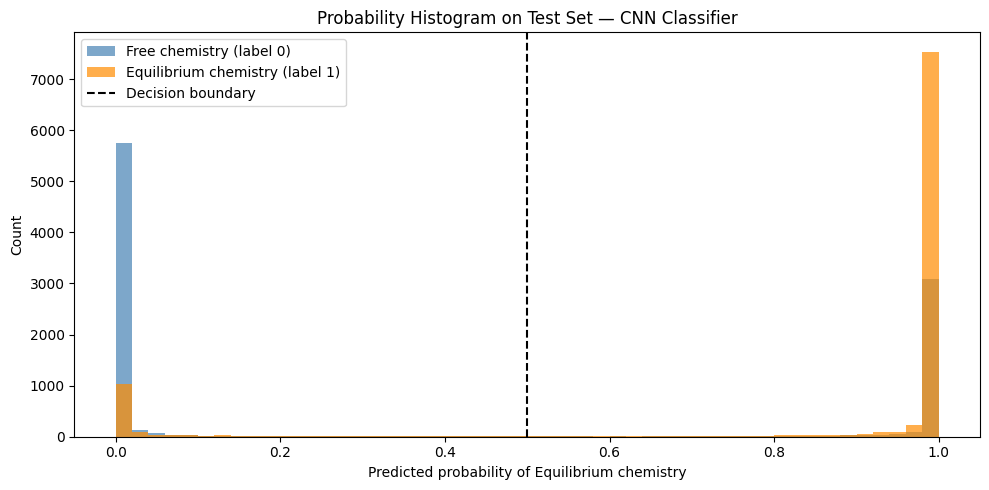

In [ ]:
# ── 2. PREDICTION PROBABILITY HISTOGRAM (test set) ────────────────────────────
# A well-calibrated, confident classifier should push probabilities toward 0 and 1.
# Plotting per-class lets you see whether the two classes are separated.

model_clf.eval()
with torch.no_grad():
    test_pred = model_clf(X_test_t).numpy().flatten()  # probabilities in [0,1]
    test_labels = (test_pred > 0.5).astype(float)

y_test_np = y_test if isinstance(y_test, np.ndarray) else y_test.numpy()

prob_free = test_pred[y_test_np == 0]   # true label = 0 (Free chemistry)
prob_eq   = test_pred[y_test_np == 1]   # true label = 1 (Equilibrium chemistry)

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 51)
ax.hist(prob_free, bins=bins, color='steelblue', alpha=0.7, label='Free chemistry (label 0)')
ax.hist(prob_eq,   bins=bins, color='darkorange', alpha=0.7, label='Equilibrium chemistry (label 1)')
ax.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Decision boundary')
ax.set_xlabel('Predicted probability of Equilibrium chemistry')
ax.set_ylabel('Count')
ax.set_title('Probability Histogram on Test Set — CNN Classifier')
ax.legend()
plt.tight_layout()
plt.savefig('probability_histogram.png', dpi=150)
plt.show()


 Random Forest  (trained in 326.7s)
 Accuracy : 0.7801
 ROC-AUC  : 0.8934
              precision    recall  f1-score   support

        Free       0.79      0.76      0.78      9850
 Equilibrium       0.77      0.80      0.79      9849

    accuracy                           0.78     19699
   macro avg       0.78      0.78      0.78     19699
weighted avg       0.78      0.78      0.78     19699



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [03:34:49] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



 XGBoost  (trained in 16.8s)
 Accuracy : 0.7818
 ROC-AUC  : 0.8946
              precision    recall  f1-score   support

        Free       0.80      0.76      0.78      9850
 Equilibrium       0.77      0.80      0.79      9849

    accuracy                           0.78     19699
   macro avg       0.78      0.78      0.78     19699
weighted avg       0.78      0.78      0.78     19699



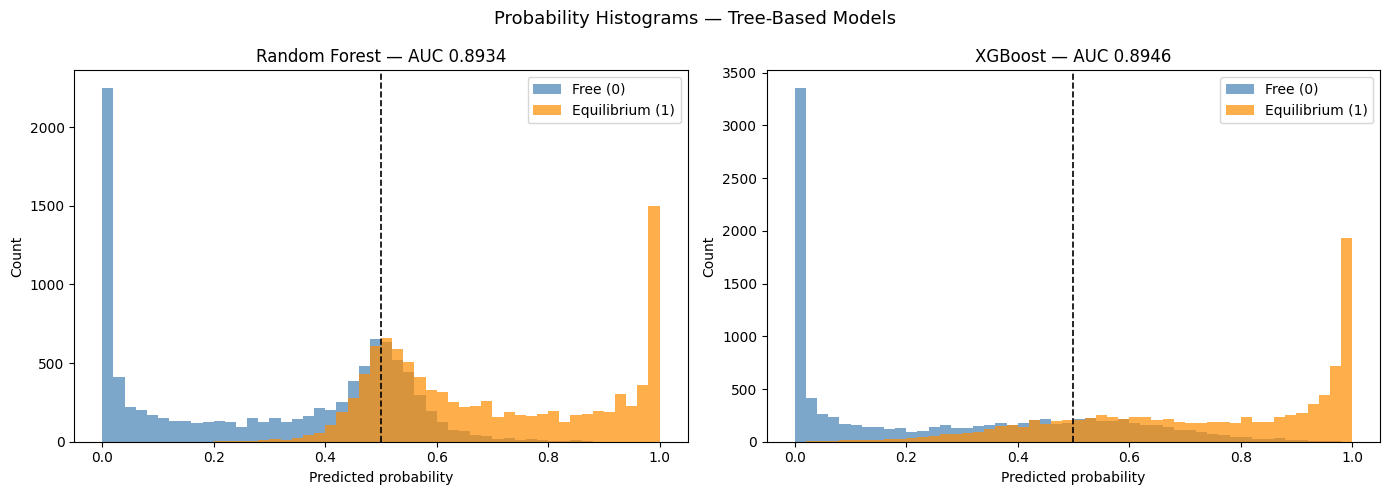


─────────────────────────────────────────────
Model                    Accuracy        AUC
─────────────────────────────────────────────
CNN (SpectralClf)          0.7422     0.7554
Random Forest              0.7801     0.8934
XGBoost                    0.7818     0.8946
─────────────────────────────────────────────


In [ ]:
# ── 3. XGBOOST & RANDOM FOREST COMPARISON ────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
import time

# Use flat (non-normalised) features — trees don't need scaling,
# but we reuse the same normalised split for a fair comparison with the CNN.
# X_train / X_test are already normalised numpy arrays.

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=None, n_jobs=-1, random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        use_label_encoder=False, eval_metric='logloss',
        random_state=42, n_jobs=-1
    ),
}

results = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, clf) in zip(axes, models.items()):
    t0 = time.time()
    clf.fit(X_train, y_train)
    elapsed = time.time() - t0

    proba = clf.predict_proba(X_test)[:, 1]
    preds = (proba > 0.5).astype(float)
    auc   = roc_auc_score(y_test, proba)
    acc   = (preds == y_test).mean()
    results[name] = dict(auc=auc, acc=acc, proba=proba)

    print(f"\n{'='*55}")
    print(f" {name}  (trained in {elapsed:.1f}s)")
    print(f"{'='*55}")
    print(f" Accuracy : {acc:.4f}")
    print(f" ROC-AUC  : {auc:.4f}")
    print(classification_report(y_test, preds, target_names=['Free', 'Equilibrium']))

    # Probability histogram
    bins = np.linspace(0, 1, 51)
    ax.hist(proba[y_test == 0], bins=bins, color='steelblue',   alpha=0.7, label='Free (0)')
    ax.hist(proba[y_test == 1], bins=bins, color='darkorange',  alpha=0.7, label='Equilibrium (1)')
    ax.axvline(0.5, color='black', linestyle='--', linewidth=1.2)
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Count')
    ax.set_title(f'{name} — AUC {auc:.4f}')
    ax.legend()

plt.suptitle('Probability Histograms — Tree-Based Models', fontsize=13)
plt.tight_layout()
plt.savefig('tree_models_prob_histograms.png', dpi=150)
plt.show()

# ── Summary comparison table ───────────────────────────────────────────────────
print("\n" + "─"*45)
print(f"{'Model':<22} {'Accuracy':>10} {'AUC':>10}")
print("─"*45)

# Add CNN result for easy comparison
cnn_auc = roc_auc_score(y_test, test_pred)
cnn_acc = (test_labels == y_test).mean()
print(f"{'CNN (SpectralClf)':<22} {cnn_acc:>10.4f} {cnn_auc:>10.4f}")

for name, r in results.items():
    print(f"{name:<22} {r['acc']:>10.4f} {r['auc']:>10.4f}")
print("─"*45)


In [ ]:
# ── REBUILD TRAIN/VAL/TEST WITH Z-SCORE DATA ─────────────────────────────────
X_z = np.vstack([spectra_free_zscore, spectra_eq_zscore]).astype(np.float32)
y_z = np.concatenate([label_free, label_eq]).astype(np.float32)

X_train_z, X_test_z, y_train_z, y_test_z = train_test_split(X_z, y_z, test_size=0.2, stratify=y_z, random_state=42)
X_val_z,   X_test_z, y_val_z,   y_test_z = train_test_split(X_test_z, y_test_z, test_size=0.5, stratify=y_test_z, random_state=42)

# Tensors for CNN
X_train_zt, y_train_zt = to_tensor(X_train_z, y_train_z)
X_val_zt,   y_val_zt   = to_tensor(X_val_z,   y_val_z)
X_test_zt,  y_test_zt  = to_tensor(X_test_z,  y_test_z)

train_loader_z = DataLoader(TensorDataset(X_train_zt, y_train_zt), batch_size=256, shuffle=True)
val_loader_z   = DataLoader(TensorDataset(X_val_zt,   y_val_zt),   batch_size=256)

# ── CNN on Z-score ────────────────────────────────────────────────────────────
model_z = SpectralChemistryClassifier()
optimizer_z  = torch.optim.Adam(model_z.parameters(), lr=1e-3)
scheduler_z  = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_z, patience=5, factor=0.5)
best_val_z   = float('inf')

for epoch in range(n_epochs):
    model_z.train()
    for X_batch, y_batch in train_loader_z:
        optimizer_z.zero_grad()
        loss = criterion(model_z(X_batch), y_batch)
        loss.backward()
        optimizer_z.step()

    model_z.eval()
    with torch.no_grad():
        val_pred_z = model_z(X_val_zt)
        val_loss_z = criterion(val_pred_z, y_val_zt).item()
    scheduler_z.step(val_loss_z)
    if val_loss_z < best_val_z:
        best_val_z = val_loss_z
        torch.save(model_z.state_dict(), 'best_classifier_zscore.pth')

model_z.load_state_dict(torch.load('best_classifier_zscore.pth'))
model_z.eval()
with torch.no_grad():
    test_pred_z = model_z(X_test_zt).numpy().flatten()
cnn_z_auc = roc_auc_score(y_test_z, test_pred_z)
cnn_z_acc = ((test_pred_z > 0.5) == y_test_z).mean()
print(f"CNN (Z-score)  Acc: {cnn_z_acc:.4f}  AUC: {cnn_z_auc:.4f}")

# ── RF + XGBoost on Z-score ───────────────────────────────────────────────────
models_z = {
    'Random Forest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
    'XGBoost':       XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                   subsample=0.8, colsample_bytree=0.8,
                                   eval_metric='logloss', random_state=42, n_jobs=-1),
}

print(f"\n{'─'*50}")
print(f"{'Model':<25} {'Acc (mean)':>10} {'Acc (zscore)':>13} {'AUC (mean)':>11} {'AUC (zscore)':>13}")
print(f"{'─'*50}")

# CNN row
with torch.no_grad():
    test_pred_mean = model_clf(X_test_t).numpy().flatten()
cnn_mean_auc = roc_auc_score(y_test, test_pred_mean)
cnn_mean_acc = ((test_pred_mean > 0.5) == y_test).mean()
print(f"{'CNN':<25} {cnn_mean_acc:>10.4f} {cnn_z_acc:>13.4f} {cnn_mean_auc:>11.4f} {cnn_z_auc:>13.4f}")

for name, clf in models_z.items():
    clf.fit(X_train_z, y_train_z)
    proba_z = clf.predict_proba(X_test_z)[:, 1]
    acc_z   = ((proba_z > 0.5) == y_test_z).mean()
    auc_z   = roc_auc_score(y_test_z, proba_z)

    # re-use already-trained mean-norm models from earlier cell for comparison
    clf_mean = models[name]
    proba_m  = clf_mean.predict_proba(X_test)[:, 1]
    acc_m    = ((proba_m > 0.5) == y_test).mean()
    auc_m    = roc_auc_score(y_test, proba_m)

    print(f"{name:<25} {acc_m:>10.4f} {acc_z:>13.4f} {auc_m:>11.4f} {auc_z:>13.4f}")

print(f"{'─'*50}")

CNN (Z-score)  Acc: 0.7843  AUC: 0.8951

──────────────────────────────────────────────────
Model                     Acc (mean)  Acc (zscore)  AUC (mean)  AUC (zscore)
──────────────────────────────────────────────────
CNN                           0.7422        0.7843      0.7554        0.8951
Random Forest                 0.7801        0.7838      0.8934        0.8926
XGBoost                       0.7818        0.7873      0.8946        0.8975
──────────────────────────────────────────────────
